# 06 — Study results, uncertainty, and implementation audit

Run after notebook 05 completes. This notebook reads saved results, checks completion and decision support, distinguishes feasible comparisons from unconstrained policy differences, and writes the final Markdown report. It does not tune or fit another model.

All figures and tables describe the specified simulated environments and 200-vehicle portfolios. The public calibration data contain bargaining, while binding floors define an explicit alternative trading institution. No results imply gains in real auctions.


In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
from IPython.display import display
OUT=Path('data/study')
results=pd.read_csv(OUT/'all_policy_results.csv')
summary=pd.read_csv(OUT/'policy_summary.csv')
boot=pd.read_csv(OUT/'bootstrap_results.csv')
metadata=json.loads((OUT/'study_metadata.json').read_text())
main=['binding_historical','binding_randomized','bargaining_historical','bargaining_randomized']
assert all(results.loc[results.scenario.eq(s),'replication'].nunique()==30 for s in main)
assert all(results.loc[results.scenario.eq('sensitivity_'+s),'replication'].nunique()==30 for s in metadata['sensitivities'])
assert boot.bootstrap.nunique()==500
assert not results.loc[results.available.eq(True),'expected_value'].isna().any()
solver_counts=results.groupby(['scenario','policy','solver_status'],dropna=False).size().rename('count').reset_index()
solver_counts.to_csv(OUT/'solver_status_counts.csv',index=False)
# Numeric integration can make feasibility ambiguous close to a target.
numerics=pd.read_csv(OUT/'oracle_numerical_checks.csv')
max_q_error=float(numerics.max_q_error.max());max_value_error=float(numerics.max_gross_error.max())
results['near_numerical_conversion_boundary']=(results.expected_conversion-results.target).abs().le(max_q_error)
results.to_csv(OUT/'policy_results_with_numerical_flags.csv',index=False)
# A common candidate set implies a nonincreasing oracle value frontier, allowing the solver gap.
frontier_issues=[]
for (scenario,rep),g in results[results.policy.eq('oracle')&results.available.eq(True)].groupby(['scenario','replication']):
    if (g.sort_values('target').expected_value.diff().dropna()>.05).any():frontier_issues.append((scenario,int(rep)))
assert not frontier_issues, frontier_issues
print('Verified: 30 replications per main/sensitivity scenario; 500 bootstraps; oracle frontiers consistent.')


Verified: 30 replications per main/sensitivity scenario; 500 bootstraps; oracle frontiers consistent.


## Independent oracle and support verification

Check the reference candidate bounds and compare integrated values against fresh Monte Carlo draws from the exact empirical-residual posterior at interior reference floors. These draws are used only to validate the numerical calculation.


In [2]:
# Independent Monte Carlo check of the reference oracle at fixed candidate interventions.
import cloudpickle
from scipy.special import expit
from scipy.stats import norm
study=json.loads(Path('05_single_run_policy_study.ipynb').read_text())
env={'__name__':'study_verification'}
for index in [1,2,4,5,7,9]:
    exec(''.join(study['cells'][index]['source']),env)
with (OUT/'reference_state.pkl').open('rb') as f:reference_model,tr,va,te=cloudpickle.load(f)
portfolio=te.sample(200,random_state=46940).reset_index(drop=True)
maps=env['support_fit'](tr)
grid,_=env['candidates'](portfolio,maps,1.0,0.0)
lo,hi,_=env['bounds_for'](portfolio,maps)
assert ((grid>=lo[:,None]-1e-10)&(grid<=hi[:,None]+1e-10)).all()
original=portfolio.head(6)
small_grid=grid[:6][:,[0,5,10]]
q_integrated,g_integrated=env['oracle'](original,small_grid,'historical','binding')
rng=np.random.default_rng(91740);mc_rows=[]
for i,(_,vehicle) in enumerate(original.iterrows()):
    f=env['fits'][vehicle.seller_group];cfg=env['CONFIG'];meta=env['metadata']
    one=original.iloc[[i]].copy()
    mu=float(f['floor'][0].predict(env['model_frame'](one))[0])
    low,high=f['floor_ratio_bounds']
    if not low<vehicle.floor_ratio<high:
        continue  # Boundary cases are covered by resolution diagnostics, not this interior check.
    residual=f['floor'][1]
    latent_values=(np.log(float(vehicle.floor_ratio))-mu-residual)/cfg['private_floor_strength']
    logweights=-.5*latent_values**2;weights=np.exp(logweights-logweights.max());weights/=weights.sum()
    u=rng.choice(latent_values,size=100000,p=weights)
    shock=rng.normal(0,cfg['market_sd'],len(u))
    for j,a in enumerate(small_grid[i]):
        z=env['model_frame'](one.assign(floor_ratio=a))
        conv=f['conversion'];slope=conv.steps[-1][1].coef_[0,3]/conv.steps[0][1].named_transformers_['num'].scale_[-1]
        base=float(conv.decision_function(z)[0])-slope*a+cfg['floor_effect']*a+meta['conversion_intercept_adjustments'][vehicle.seller_group]
        q=expit(base+cfg['private_sale_strength']*u+shock)
        reg,resid=f['binding'];ordered=np.sort(resid);delta=np.diff(ordered)
        smear=(np.exp(ordered[:-1])*np.divide(np.expm1(delta),delta,out=np.ones_like(delta),where=delta!=0)).mean()
        premium=np.exp(float(reg.predict(z)[0]))*meta['price_calibration'][vehicle.seller_group+'_binding']['multiplier']*smear
        price=float(vehicle.benchmark)*(a+premium*np.exp(cfg['private_price_strength']*u))
        gross=q*price
        qse=q.std(ddof=1)/np.sqrt(len(q));gse=gross.std(ddof=1)/np.sqrt(len(gross))
        mc_rows.append(dict(vehicle=i,floor_ratio=a,q_oracle=q_integrated[i,j],q_mc=q.mean(),q_mcse=qse,
                gross_oracle=g_integrated[i,j],gross_mc=gross.mean(),gross_mcse=gse))
        assert abs(q_integrated[i,j]-q.mean()) < 5*qse+max_q_error
        assert abs(g_integrated[i,j]-gross.mean()) < 5*gse+max_value_error
mc=pd.DataFrame(mc_rows);mc.to_csv(OUT/'oracle_monte_carlo_check.csv',index=False)
assert len(mc)>=9
print('Oracle agrees with independently sampled posterior outcomes within Monte Carlo and integration tolerance.')

# Assess candidate interventions, not just historical-assignment calibration.
expanded=portfolio.loc[portfolio.index.repeat(grid.shape[1])].copy()
expanded['floor_ratio']=grid.ravel()
qh,ph=env['predict'](reference_model,expanded)
qt,gt=env['oracle'](portfolio,grid,'historical','binding')
response=expanded[['vehicle_id','seller_group','floor_ratio']].copy().reset_index(drop=True)
response['predicted_conversion']=qh;response['oracle_conversion']=qt.ravel()
response['predicted_price']=ph;response['oracle_conditional_price']=(gt/qt).ravel()
response=response.drop_duplicates(['vehicle_id','floor_ratio'])
response['floor_band']=pd.cut(response.floor_ratio,[0,.75,1,1.25,1.5,2,np.inf]).astype(str)
response.to_csv(OUT/'candidate_response_diagnostics.csv',index=False)
response_groups=response.groupby(['seller_group','floor_band']).agg(
    candidate_points=('vehicle_id','size'),predicted_conversion=('predicted_conversion','mean'),
    oracle_conversion=('oracle_conversion','mean'),predicted_price=('predicted_price','mean'),
    oracle_conditional_price=('oracle_conditional_price','mean')).reset_index()
response_groups.to_csv(OUT/'candidate_response_group_summary.csv',index=False)
order=np.argsort(grid,axis=1)
qt_sorted=np.take_along_axis(qt,order,axis=1)
qh_sorted=np.take_along_axis(qh.reshape(grid.shape),order,axis=1)
assert (np.diff(qt_sorted,axis=1)<=1e-8).all()
monotonicity=dict(vehicles=len(portfolio),predicted_increase_fraction=float((np.diff(qh_sorted,axis=1)>1e-6).any(axis=1).mean()),
                  oracle_increase_fraction=0.0)
(OUT/'candidate_monotonicity.json').write_text(json.dumps(monotonicity,indent=2))
print('Candidate response diagnostics and support checks saved.')


Oracle agrees with independently sampled posterior outcomes within Monte Carlo and integration tolerance.


Candidate response diagnostics and support checks saved.


## Feasible policy comparisons and sensitivity contrasts

A positive value difference alone does not establish dominance if conversion requirements differ. The following table restricts each paired comparison to replications where both policies satisfy the integrated expected-conversion constraint. The ordinary all-pair table remains available separately; both sample counts are reported. Feasibility uses the numerical oracle and is flagged near its integration resolution.

Sensitivity contrasts pair equal seeds with the main binding/historical environment. Because scenarios differ intentionally, these are within-simulation changes, not causal estimates for observed auctions.


In [3]:
def summarize_delta(delta):
    delta=delta.dropna();n=len(delta)
    mean=delta.mean() if n else np.nan;se=delta.std(ddof=1)/np.sqrt(n) if n>1 else np.nan
    margin=student_t.ppf(.975,n-1)*se if n>1 else np.nan
    return dict(n=n,mean=mean,mcse=se,lower=mean-margin,upper=mean+margin)
feasible_rows=[]
for (scenario,target),g in results.groupby(['scenario','target']):
    opt=g[g.policy.eq('optimized')].set_index('replication')
    for baseline in ['assigned_supported','common','proportional_reduction']:
        other=g[g.policy.eq(baseline)].set_index('replication')
        pair=opt[['expected_value','true_feasible','near_numerical_conversion_boundary']].join(
             other[['expected_value','true_feasible','near_numerical_conversion_boundary']],lsuffix='_optimized',rsuffix='_baseline',how='inner')
        ok=pair.true_feasible_optimized.eq(True)&pair.true_feasible_baseline.eq(True)
        safe=ok&~pair.near_numerical_conversion_boundary_optimized&~pair.near_numerical_conversion_boundary_baseline
        for label,use in [('both_feasible',ok),('both_feasible_away_from_numeric_boundary',safe)]:
            delta=pair.loc[use,'expected_value_optimized']-pair.loc[use,'expected_value_baseline']
            feasible_rows.append(dict(scenario=scenario,target=target,baseline=baseline,comparison=label,**summarize_delta(delta)))
feasible=pd.DataFrame(feasible_rows);feasible.to_csv(OUT/'feasible_paired_value_differences.csv',index=False)
sensitivity=[]
base=results[results.scenario.eq('binding_historical')&results.policy.eq('optimized')&results.target.eq(.6)].set_index('replication')
for name in metadata['sensitivities']:
    g=results[results.scenario.eq('sensitivity_'+name)&results.policy.eq('optimized')].set_index('replication')
    for metric in ['expected_value','expected_conversion']:
        sensitivity.append(dict(scenario=name,metric=metric,**summarize_delta(g[metric]-base[metric])))
sensitivity=pd.DataFrame(sensitivity);sensitivity.to_csv(OUT/'paired_sensitivity_effects.csv',index=False)
display(summary[summary.target.eq(.6)&summary.scenario.isin(main)])


,scenario,target,policy,replications,availability,expected_conversion,expected_value,expected_gross,true_feasible_rate,realized_shortfall_rate,regret
10,bargaining_historical,0.6,assigned_supported,30,1.0,0.512185,7950.079233,4864.768859,0.000000,0.966667,NaN
11,bargaining_historical,0.6,common,30,1.0,0.652878,8014.617100,5535.586107,1.000000,0.033333,322.475674
12,bargaining_historical,0.6,optimized,30,1.0,0.660359,8196.517491,5339.695673,1.000000,0.033333,140.575282
13,bargaining_historical,0.6,oracle,30,1.0,0.600002,8337.092774,5231.857838,1.000000,0.433333,0.000000
14,bargaining_historical,0.6,proportional_reduction,30,1.0,0.622927,7736.861559,5411.340045,0.833333,0.266667,620.460592
35,bargaining_randomized,0.6,assigned_supported,30,1.0,0.536956,7895.099163,4724.753853,0.000000,0.933333,NaN
36,bargaining_randomized,0.6,common,30,1.0,0.652608,8011.861815,5528.460453,1.000000,0.033333,326.080485
37,bargaining_randomized,0.6,optimized,30,1.0,0.653866,8191.176542,5327.126025,1.000000,0.000000,146.765758
38,bargaining_randomized,0.6,oracle,30,1.0,0.600002,8337.942300,5205.924389,1.000000,0.433333,0.000000
39,bargaining_randomized,0.6,proportional_reduction,30,1.0,0.624196,7727.578057,5167.195465,0.833333,0.166667,628.151386


## Results 1-2: source audit, calibration, and synthetic data

The first two Methods subsections describe the source audit and synthetic-data generator. The figures below therefore show the analyzed source population, the generated population, distributional agreement, and the intended differences among simulation scenarios. Source records are read only for these diagnostics; no source file is modified.


/var/folders/qk/h9ncn2v54gb9mbzz0vjllrz80000gn/T/ipykernel_39153/1607669794.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date=pd.to_datetime(d.history_run_date,errors='coerce')
/var/folders/qk/h9ncn2v54gb9mbzz0vjllrz80000gn/T/ipykernel_39153/1607669794.py:21: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  date=pd.to_datetime(d.history_run_date,errors='coerce')


,dataset,seller_group,n,conversion,age_median,mileage_median,benchmark_median,floor_ratio_median,sold_price_ratio_median
0,Source,dealer,300740,0.357,6.0,93850.500,5900.000,1.116,0.933
1,Source,fleet_lease,211656,0.722,3.0,50627.000,9550.000,0.947,0.920
2,Synthetic,dealer,29340,0.335,6.0,83365.493,5678.963,1.156,0.961
3,Synthetic,fleet_lease,20660,0.693,3.0,44633.748,9074.882,0.952,0.934


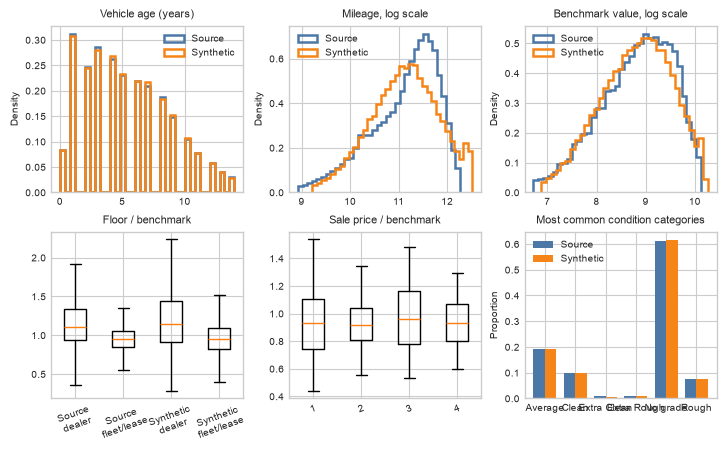

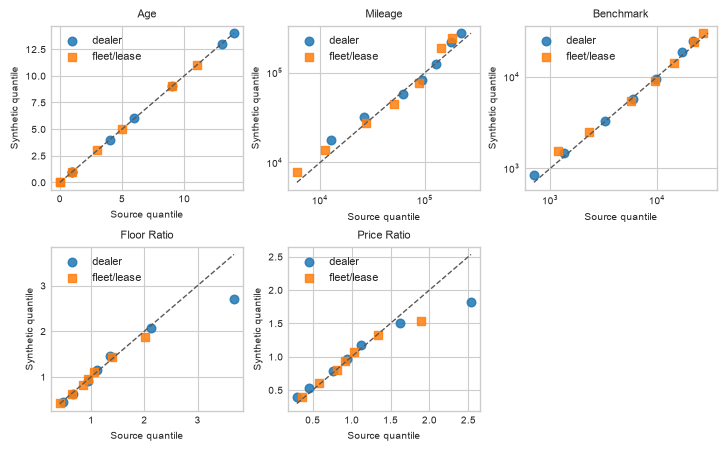

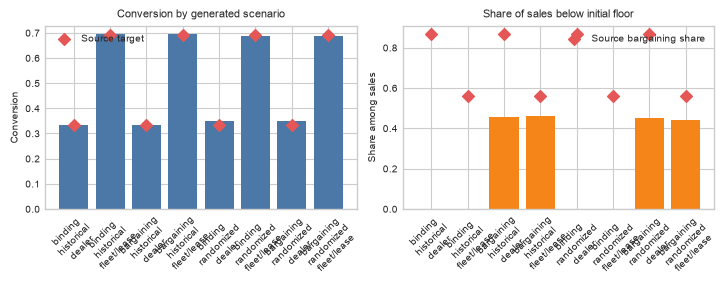

In [4]:
# Load source and generated data for paper-ready descriptive evidence.
CAL=Path('data/calibration'); TRAIN=Path('data/training/binding_historical')
FIG=OUT/'figures';FIG.mkdir(exist_ok=True)
# PAPER=True writes untitled, print-sized figures to paper/figures (titles come from the LaTeX captions);
# PAPER=False writes the full-size titled figures to data/study/figures.
PAPER=True
SCALE=.55 if PAPER else 1.0
def scaled(width,height): return (width*SCALE,height*SCALE)
def figtitle(fig,text):
    if not PAPER: fig.suptitle(text,fontsize=14)
if PAPER:
    FIG=Path('paper/figures');FIG.mkdir(parents=True,exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
if PAPER: plt.rcParams.update({'font.size':7.5,'axes.titlesize':8,'legend.fontsize':7,'savefig.dpi':300})
COLORS={'Source':'#4C78A8','Synthetic':'#F58518','Predicted':'#4C78A8','Observed':'#E45756','Oracle':'#54A24B'}

source_parts=[]
for filename,group in [('pre_step1_ins0.csv','dealer'),('pre_step1_ins1.csv','fleet_lease')]:
    use=['history_run_date','year','odo','bb','low','agree','finalprice','conrepgrade']
    d=pd.read_csv(Path('Larsen_used_car_bargaining_data_and_code')/filename,usecols=use)
    date=pd.to_datetime(d.history_run_date,errors='coerce')
    d=d.assign(seller_group=group,age=date.dt.year-pd.to_numeric(d.year,errors='coerce'),
               mileage=pd.to_numeric(d.odo,errors='coerce'),benchmark=pd.to_numeric(d.bb,errors='coerce'),
               floor=pd.to_numeric(d.low,errors='coerce'),sold=pd.to_numeric(d.agree,errors='coerce'),
               price=pd.to_numeric(d.finalprice,errors='coerce'),condition=d.conrepgrade)
    d['floor_ratio']=d.floor/d.benchmark
    d['price_ratio']=d.price/d.benchmark
    source_parts.append(d[['seller_group','age','mileage','benchmark','floor_ratio','sold','price','price_ratio','condition']])
source=pd.concat(source_parts,ignore_index=True)
source=source[(source.age.ge(0)|source.age.isna()) & (source.mileage.ge(0)|source.mileage.isna())]
synthetic=pd.read_csv('data/synthetic/binding_historical.csv')
synthetic['price_ratio']=synthetic.price/synthetic.benchmark

def describe_frame(d,label):
    rows=[]
    for group,g in d.groupby('seller_group'):
        rows.append(dict(dataset=label,seller_group=group,n=len(g),conversion=g.sold.mean(),
                         age_median=g.age.median(),mileage_median=g.mileage.median(),
                         benchmark_median=g.benchmark.median(),floor_ratio_median=g.floor_ratio.median(),
                         sold_price_ratio_median=g.loc[g.sold.eq(1),'price_ratio'].median()))
    return rows
dataset_summary=pd.DataFrame(describe_frame(source,'Source')+describe_frame(synthetic,'Synthetic'))
dataset_summary.to_csv(OUT/'paper_dataset_summary.csv',index=False)
display(dataset_summary.round(3))

# Figure 1: histograms and box plots requested for the generated data audit.
fig,axes=plt.subplots(2,3,figsize=scaled(13,8),layout='constrained')
for ax,var,title,transform in [
    (axes[0,0],'age','Vehicle age (years)',lambda x:x),
    (axes[0,1],'mileage','Mileage, log scale',lambda x:np.log1p(x)),
    (axes[0,2],'benchmark','Benchmark value, log scale',lambda x:np.log(x))]:
    for data,label in [(source,'Source'),(synthetic,'Synthetic')]:
        x=transform(pd.to_numeric(data[var],errors='coerce').dropna())
        lo,hi=x.quantile([.01,.99]);x=x[x.between(lo,hi)]
        ax.hist(x,bins=35,density=True,histtype='step',linewidth=1.8,label=label,color=COLORS[label])
    ax.set_title(title);ax.set_ylabel('Density');ax.legend()
box_data=[];box_labels=[]
for label,data in [('Source',source),('Synthetic',synthetic)]:
    for group in ['dealer','fleet_lease']:
        x=pd.to_numeric(data.loc[data.seller_group.eq(group),'floor_ratio'],errors='coerce').dropna()
        box_data.append(x[x.le(x.quantile(.99))]);box_labels.append(f'{label}\n{group.replace("_","/")}')
axes[1,0].boxplot(box_data,tick_labels=box_labels,showfliers=False);axes[1,0].set_title('Floor / benchmark');axes[1,0].tick_params(axis='x',labelrotation=20)
price_data=[];price_labels=[]
for label,data in [('Source',source),('Synthetic',synthetic)]:
    for group in ['dealer','fleet_lease']:
        x=pd.to_numeric(data.loc[data.seller_group.eq(group)&data.sold.eq(1),'price_ratio'],errors='coerce').dropna()
        price_data.append(x[x.le(x.quantile(.99))]);price_labels.append(f'{label}\n{group.replace("_","/")}')
axes[1, 1].boxplot(price_data, whis=(5, 95), showfliers=False);axes[1,1].set_title('Sale price / benchmark');axes[1,1].tick_params(axis='x',labelrotation=20)
# axes[1, 1].boxplot(price_data, tick_labels=price_labels, showfliers=False)
# axes[1, 1].set_title("Sale price / benchmark")
# axes[1, 1].tick_params(axis="x", labelrotation=20)
cond=[]
for label,data in [('Source',source),('Synthetic',synthetic)]:
    p=data.condition.astype(str).value_counts(normalize=True).head(6)
    for cat,val in p.items():cond.append((label,cat,val))
cond=pd.DataFrame(cond,columns=['dataset','condition','proportion'])
cats=sorted(set(cond.condition));x=np.arange(len(cats));w=.38
for j,label in enumerate(['Source','Synthetic']):
    vals=cond[cond.dataset.eq(label)].set_index('condition').proportion.reindex(cats,fill_value=0)
    axes[1,2].bar(x+(j-.5)*w,vals,w,label=label,color=COLORS[label])
axes[1,2].set(xticks=x,xticklabels=cats,title='Most common condition categories',ylabel='Proportion');axes[1,2].legend()
figtitle(fig,'Figure 1. Source and binding/historical synthetic distributions')
fig.savefig(FIG/'01_source_synthetic_distributions.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 2: quantile agreement gives a direct calibration check at seven quantiles.
quant=pd.read_csv(CAL/'quantile_comparison.csv')
quant=quant[quant.scenario.eq('binding_historical')]
fields=['age','mileage','benchmark','floor_ratio','price_ratio']
fig,axes=plt.subplots(2,3,figsize=scaled(13,8),layout='constrained');axes=axes.ravel()
for ax,field in zip(axes,fields):
    d=quant[quant.field.eq(field)]
    for group,mark in [('dealer','o'),('fleet_lease','s')]:
        g=d[d.group.eq(group)];ax.scatter(g.source,g.synthetic,label=group.replace('_','/'),marker=mark,s=38,alpha=.85)
    low=min(d.source.min(),d.synthetic.min());high=max(d.source.max(),d.synthetic.max())
    ax.plot([low,high],[low,high],'--',color='0.35',linewidth=1);ax.set(title=field.replace('_',' ').title(),xlabel='Source quantile',ylabel='Synthetic quantile')
    if field in ['mileage','benchmark']:ax.set_xscale('log');ax.set_yscale('log')
    ax.legend(fontsize=8)
axes[-1].axis('off')
figtitle(fig,'Figure 2. Calibration quantile agreement')
fig.savefig(FIG/'02_calibration_quantile_agreement.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 3: scenario checks make the trading-institution assumptions visible.
scenario=pd.read_csv(CAL/'scenario_comparison.csv')
scenario['label']=scenario.scenario.str.replace('_','\n')+'\n'+scenario.group.str.replace('_','/')
fig,axes=plt.subplots(1,2,figsize=scaled(13,5),layout='constrained');x=np.arange(len(scenario))
axes[0].bar(x,scenario.realized_conversion,color='#4C78A8');axes[0].scatter(x,scenario.source_conversion,color='#E45756',marker='D',label='Source target',zorder=3)
axes[0].set(xticks=x,xticklabels=scenario.label,title='Conversion by generated scenario',ylabel='Conversion');axes[0].tick_params(axis='x',labelrotation=45);axes[0].legend()
axes[1].bar(x,scenario.synthetic_below_reserve_share,color='#F58518');axes[1].scatter(x,scenario.source_below_reserve_share,color='#E45756',marker='D',label='Source bargaining share',zorder=3)
axes[1].set(xticks=x,xticklabels=scenario.label,title='Share of sales below initial floor',ylabel='Share among sales');axes[1].tick_params(axis='x',labelrotation=45);axes[1].legend()
figtitle(fig,'Figure 3. Generated outcomes across institutional scenarios')
fig.savefig(FIG/'03_scenario_outcomes.png',dpi=200,bbox_inches='tight');plt.show()


## Results 3: conversion and conditional-price prediction

The third Methods subsection specifies separate models for sale probability and price conditional on sale. Model-selection results, held-out calibration, dollar-error metrics, and floor-range diagnostics are reported separately because good average prediction does not guarantee good decisions at candidate floors.


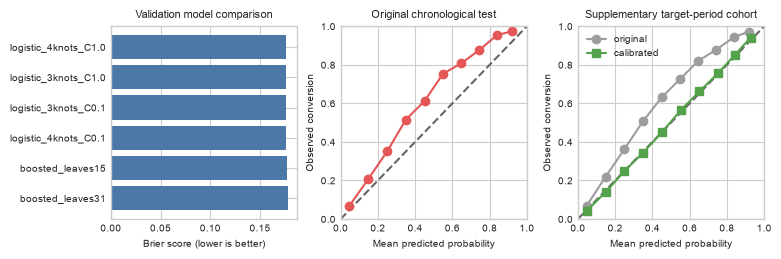

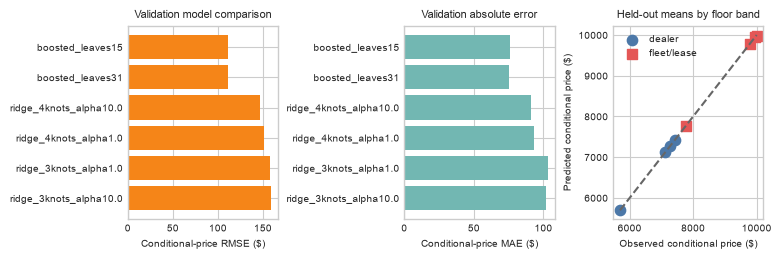

,model,log_loss,brier,roc_auc,price_mae,price_rmse,price_bias,gross_mae,gross_rmse,gross_bias
0,selected,0.557,0.189,0.823,77.624,114.109,-8.726,3423.562,4834.988,-1176.683
1,training_constant_reference,0.697,0.252,0.500,804.797,1743.294,679.607,4477.789,5490.602,-54.037


In [5]:
# Figure 4: conversion model selection and calibration evidence.
classification=pd.read_csv(TRAIN/'validation_classification.csv').sort_values('brier')
reliability=pd.read_csv(TRAIN/'test_reliability.csv')
repair=pd.read_csv('data/training/calibration_repair/final_independent_reliability.csv')
fig,axes=plt.subplots(1,3,figsize=scaled(14,4.5),layout='constrained')
axes[0].barh(classification.model,classification.brier,color='#4C78A8');axes[0].invert_yaxis();axes[0].set(title='Validation model comparison',xlabel='Brier score (lower is better)')
axes[1].plot([0,1],[0,1],'--',color='0.4')
axes[1].plot(reliability.predicted,reliability.observed,'o-',color='#E45756');axes[1].set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed conversion',title='Original chronological test')
axes[2].plot([0,1],[0,1],'--',color='0.4')
for model,color,mark in [('original','#9D9D9D','o'),('calibrated','#54A24B','s')]:
    d=repair[repair.model.eq(model)];axes[2].plot(d.predicted,d.observed,marker=mark,label=model,color=color)
axes[2].set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted probability',ylabel='Observed conversion',title='Supplementary target-period cohort');axes[2].legend()
figtitle(fig,'Figure 4. Conversion-model selection and reliability')
fig.savefig(FIG/'04_conversion_model_performance.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 5: conditional-price model selection and held-out group diagnostics.
price_val=pd.read_csv(TRAIN/'validation_price.csv').sort_values('rmse')
price_group=pd.read_csv(TRAIN/'price_group_diagnostics.csv')
test_price=price_group[price_group.split.eq('test')].copy()
fig,axes=plt.subplots(1,3,figsize=scaled(14,4.5),layout='constrained')
axes[0].barh(price_val.model,price_val.rmse,color='#F58518');axes[0].invert_yaxis();axes[0].set(title='Validation model comparison',xlabel='Conditional-price RMSE ($)')
axes[1].barh(price_val.model,price_val.mae,color='#72B7B2');axes[1].invert_yaxis();axes[1].set(title='Validation absolute error',xlabel='Conditional-price MAE ($)')
for group,color,mark in [('dealer','#4C78A8','o'),('fleet_lease','#E45756','s')]:
    d=test_price[test_price.seller_group.eq(group)];axes[2].scatter(d.observed,d.predicted,label=group.replace('_','/'),color=color,marker=mark,s=55)
low=min(test_price.observed.min(),test_price.predicted.min());high=max(test_price.observed.max(),test_price.predicted.max());axes[2].plot([low,high],[low,high],'--',color='0.4')
axes[2].set(title='Held-out means by floor band',xlabel='Observed conditional price ($)',ylabel='Predicted conditional price ($)');axes[2].legend()
figtitle(fig,'Figure 5. Conditional-price prediction')
fig.savefig(FIG/'05_price_model_performance.png',dpi=200,bbox_inches='tight');plt.show()

test_metrics=pd.read_csv(TRAIN/'test_metrics.csv')
test_metrics.to_csv(OUT/'paper_model_metrics.csv',index=False)
display(test_metrics.round(3))


## Results 4: candidate responses and floor optimization

The fourth Methods subsection turns predicted conversion and conditional price into expected seller value and selects one supported candidate floor per vehicle. The diagnostics below show the fitted response surface against the oracle benchmark, the direction and magnitude of recommended floor changes, and the conversion-value frontier.


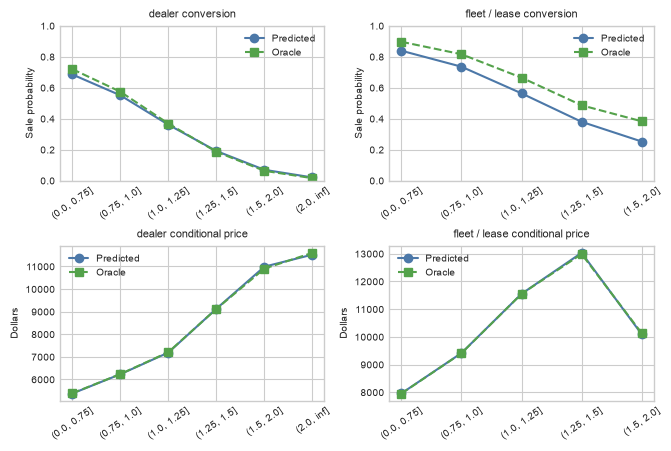

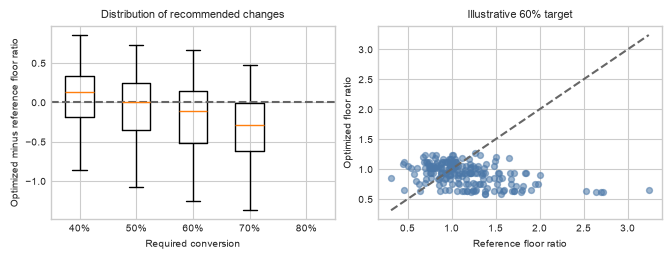

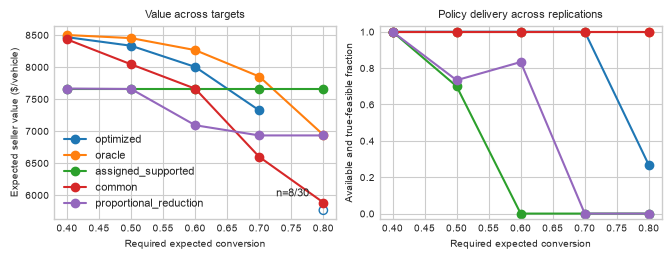

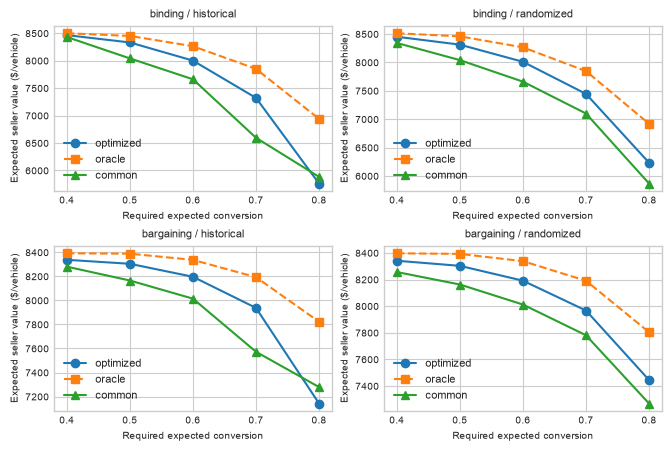

In [6]:
# Figure 6: fitted and oracle candidate responses.
cand=pd.read_csv(OUT/'candidate_response_group_summary.csv')
order=['(0.0, 0.75]','(0.75, 1.0]','(1.0, 1.25]','(1.25, 1.5]','(1.5, 2.0]','(2.0, inf]']
fig,axes=plt.subplots(2,2,figsize=scaled(12,8),layout='constrained')
for col,group in enumerate(['dealer','fleet_lease']):
    d=cand[cand.seller_group.eq(group)].copy();d['order']=d.floor_band.map({v:i for i,v in enumerate(order)});d=d.sort_values('order');x=np.arange(len(d))
    axes[0,col].plot(x,d.predicted_conversion,'o-',label='Predicted',color='#4C78A8');axes[0,col].plot(x,d.oracle_conversion,'s--',label='Oracle',color='#54A24B')
    axes[0,col].set(xticks=x,xticklabels=d.floor_band,title=group.replace('_',' / ')+' conversion',ylabel='Sale probability',ylim=(0,1));axes[0,col].tick_params(axis='x',labelrotation=35);axes[0,col].legend()
    axes[1,col].plot(x,d.predicted_price,'o-',label='Predicted',color='#4C78A8');axes[1,col].plot(x,d.oracle_conditional_price,'s--',label='Oracle',color='#54A24B')
    axes[1,col].set(xticks=x,xticklabels=d.floor_band,title=group.replace('_',' / ')+' conditional price',ylabel='Dollars');axes[1,col].tick_params(axis='x',labelrotation=35);axes[1,col].legend()
figtitle(fig,'Figure 6. Candidate-floor response diagnostics')
fig.savefig(FIG/'06_candidate_response_curves.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 7: recommended changes on the fixed reference portfolio.
decisions=pd.read_csv(OUT/'reference_decisions.csv');decisions['change']=decisions.optimized_floor_ratio-decisions.reference_floor_ratio
fig,axes=plt.subplots(1,2,figsize=scaled(12,4.5),layout='constrained')
groups=[decisions.loc[decisions.target.eq(t),'change'].dropna() for t in sorted(decisions.target.unique())]
axes[0].boxplot(groups,tick_labels=[f'{t:.0%}' for t in sorted(decisions.target.unique())],showfliers=False);axes[0].axhline(0,color='0.4',linestyle='--');axes[0].set(xlabel='Required conversion',ylabel='Optimized minus reference floor ratio',title='Distribution of recommended changes')
d=decisions[decisions.target.eq(.6)].dropna();axes[1].scatter(d.reference_floor_ratio,d.optimized_floor_ratio,s=18,alpha=.55,color='#4C78A8')
lo=min(d.reference_floor_ratio.min(),d.optimized_floor_ratio.min());hi=max(d.reference_floor_ratio.max(),d.optimized_floor_ratio.max());axes[1].plot([lo,hi],[lo,hi],'--',color='0.4');axes[1].set(xlabel='Reference floor ratio',ylabel='Optimized floor ratio',title='Illustrative 60% target')
figtitle(fig,'Figure 7. Vehicle-level floor recommendations')
fig.savefig(FIG/'07_floor_recommendations.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 8: regenerate the main frontier here so notebook 06 is self-contained.
fig,axes=plt.subplots(1,2,figsize=scaled(12,4.5),layout='constrained')
primary_frontier=summary[summary.scenario.eq('binding_historical')]
for policy in ['optimized','oracle','assigned_supported','common','proportional_reduction']:
    g=primary_frontier[primary_frontier.policy.eq(policy)].sort_values('target')
    axes[0].plot(g.target,g.expected_value.where(g.availability.eq(1)),'o-',label=policy)
    partial=g[g.availability.lt(1)]
    if len(partial):
        color=axes[0].lines[-1].get_color();axes[0].scatter(partial.target,partial.expected_value,facecolors='none',edgecolors=color)
        for _,row in partial.iterrows():axes[0].annotate(f'n={int(round(row.availability*row.replications))}/{int(row.replications)}',(row.target,row.expected_value),xytext=(-34,10),textcoords='offset points',fontsize=8)
    axes[1].plot(g.target,g.true_feasible_rate*g.availability,'o-',label=policy)
axes[0].set(xlabel='Required expected conversion',ylabel='Expected seller value ($/vehicle)',title='Value across targets')
axes[1].set(xlabel='Required expected conversion',ylabel='Available and true-feasible fraction',ylim=(-.03,1.03),title='Policy delivery across replications')
axes[0].legend(fontsize=8);figtitle(fig,'Figure 8. Conversion-value frontier: binding/historical scenario')
(not PAPER) and fig.savefig(OUT/'conversion_value_frontier.png',dpi=200,bbox_inches='tight');fig.savefig(FIG/'08_conversion_value_frontier.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 9: scenario-specific optimized and oracle frontiers.
fig,axes=plt.subplots(2,2,figsize=scaled(12,8),layout='constrained')
for ax,scenario_name in zip(axes.ravel(),main):
    d=summary[summary.scenario.eq(scenario_name)]
    for policy,style in [('optimized','o-'),('oracle','s--'),('common','^-')]:
        g=d[d.policy.eq(policy)].sort_values('target');ax.plot(g.target,g.expected_value,style,label=policy)
    ax.set(title=scenario_name.replace('_',' / '),xlabel='Required expected conversion',ylabel='Expected seller value ($/vehicle)');ax.legend(fontsize=8)
figtitle(fig,'Figure 9. Policy frontiers across four simulated environments')
fig.savefig(FIG/'09_scenario_frontiers.png',dpi=200,bbox_inches='tight');plt.show()


## Results 5: repeated evaluation, uncertainty, and sensitivity

The fifth Methods subsection requires at least 30 independent datasets per main scenario, paired policy comparisons, a 500-resample date-block bootstrap, and sensitivity experiments. The plots below show replication uncertainty, calibration across floor ranges, and how conclusions change under the nine prespecified environment changes.


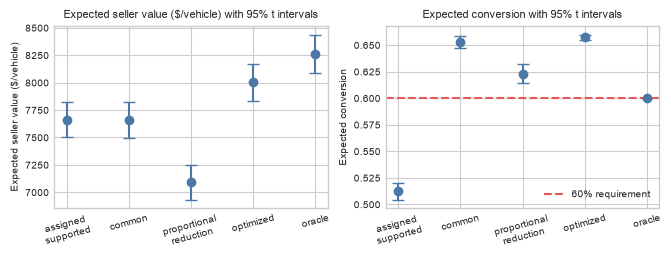

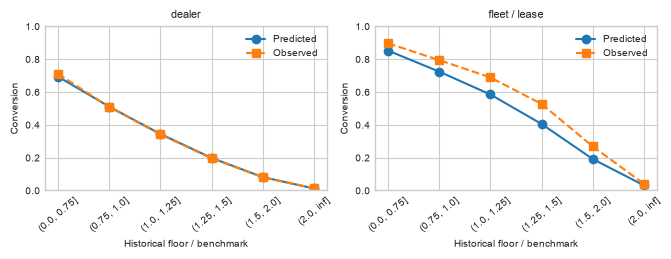

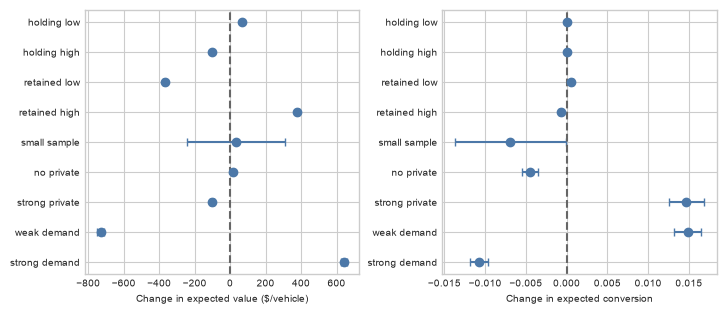

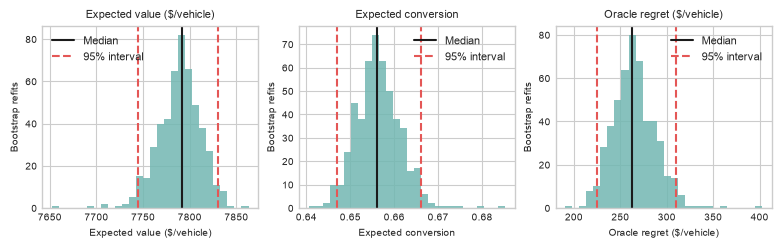

In [7]:
# Figure 10: policy comparison with replication uncertainty at the illustrative target.
d=results[results.scenario.eq('binding_historical')&results.target.eq(.6)&results.available.eq(True)].copy()
policies=['assigned_supported','common','proportional_reduction','optimized','oracle']
rows=[]
for p in policies:
    g=d[d.policy.eq(p)]
    for metric in ['expected_value','expected_conversion']:
        x=g[metric].dropna();se=x.std(ddof=1)/np.sqrt(len(x));m=student_t.ppf(.975,len(x)-1)*se if len(x)>1 else np.nan
        rows.append(dict(policy=p,metric=metric,n=len(x),mean=x.mean(),lower=x.mean()-m,upper=x.mean()+m))
comparison=pd.DataFrame(rows);comparison.to_csv(OUT/'paper_policy_comparison_60.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=scaled(12,4.5),layout='constrained')
for ax,metric,label in [(axes[0],'expected_value','Expected seller value ($/vehicle)'),(axes[1],'expected_conversion','Expected conversion')]:
    g=comparison[comparison.metric.eq(metric)].set_index('policy').reindex(policies);x=np.arange(len(g));err=np.vstack([g['mean']-g.lower,g.upper-g['mean']])
    ax.errorbar(x,g['mean'],yerr=err,fmt='o',capsize=4,color='#4C78A8');ax.set(xticks=x,xticklabels=[p.replace('_','\n') for p in policies],ylabel=label,title=label+' with 95% t intervals')
    ax.tick_params(axis='x',labelrotation=15)
    if metric=='expected_conversion':ax.axhline(.6,color='#E45756',linestyle='--',label='60% requirement');ax.legend()
figtitle(fig,'Figure 10. Illustrative policy comparison at a 60% requirement')
fig.savefig(FIG/'10_policy_comparison_60.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 11: repeated-run prediction calibration by floor range.
tables=[]
for scenario_name in main:
    for file in sorted((OUT/scenario_name).glob('prediction_groups_*.csv')):
        x=pd.read_csv(file);x['scenario']=scenario_name;tables.append(x)
groups=pd.concat(tables,ignore_index=True);groups['predicted_sales']=groups.predicted*groups.n;groups['observed_sales']=groups.observed*groups.n
pooled=groups.groupby(['scenario','seller_group','floor_band']).agg(n=('n','sum'),predicted_sales=('predicted_sales','sum'),observed_sales=('observed_sales','sum')).reset_index()
pooled['predicted']=pooled.predicted_sales/pooled.n;pooled['observed']=pooled.observed_sales/pooled.n;pooled.to_csv(OUT/'pooled_floor_range_calibration.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=scaled(12,4.5),layout='constrained')
for ax,group in zip(axes,['dealer','fleet_lease']):
    q=pooled[pooled.scenario.eq('binding_historical')&pooled.seller_group.eq(group)].copy();q['order']=q.floor_band.map({k:i for i,k in enumerate(order)});q=q.sort_values('order')
    ax.plot(q.floor_band,q.predicted,'o-',label='Predicted');ax.plot(q.floor_band,q.observed,'s--',label='Observed');ax.set(title=group.replace('_',' / '),xlabel='Historical floor / benchmark',ylabel='Conversion',ylim=(0,1));ax.tick_params(axis='x',labelrotation=40);ax.legend()
figtitle(fig,'Figure 11. Held-out conversion calibration pooled across 30 refits')
(not PAPER) and fig.savefig(OUT/'floor_range_prediction_diagnostics.png',dpi=200,bbox_inches='tight');fig.savefig(FIG/'11_floor_range_prediction_diagnostics.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 12: paired sensitivity effects at the illustrative target.
sens=pd.read_csv(OUT/'paired_sensitivity_effects.csv');labels=[x for x in sens.scenario.unique()]
fig,axes=plt.subplots(1,2,figsize=scaled(13,5.5),layout='constrained')
for ax,metric,xlabel in [(axes[0],'expected_value','Change in expected value ($/vehicle)'),(axes[1],'expected_conversion','Change in expected conversion')]:
    g=sens[sens.metric.eq(metric)].set_index('scenario').reindex(labels);y=np.arange(len(g));err=np.vstack([g['mean']-g.lower,g.upper-g['mean']])
    ax.errorbar(g['mean'],y,xerr=err,fmt='o',capsize=3,color='#4C78A8');ax.axvline(0,color='0.4',linestyle='--');ax.set(yticks=y,yticklabels=[s.replace('_',' ') for s in labels],xlabel=xlabel);ax.invert_yaxis()
figtitle(fig,'Figure 12. Paired sensitivity effects relative to the primary 60% scenario')
fig.savefig(FIG/'12_sensitivity_effects.png',dpi=200,bbox_inches='tight');plt.show()

# Figure 13: estimation uncertainty from 500 date-block bootstrap refits.
bopt=boot[boot.policy.eq('optimized')]
fig,axes=plt.subplots(1,3,figsize=scaled(14,4.3),layout='constrained')
for ax,metric,label in [(axes[0],'expected_value','Expected value ($/vehicle)'),(axes[1],'expected_conversion','Expected conversion'),(axes[2],'regret','Oracle regret ($/vehicle)')]:
    x=bopt[metric].dropna();lo,med,hi=x.quantile([.025,.5,.975]);ax.hist(x,bins=28,color='#72B7B2',alpha=.85);ax.axvline(med,color='#1B1B1B',linewidth=1.5,label='Median');ax.axvline(lo,color='#E45756',linestyle='--');ax.axvline(hi,color='#E45756',linestyle='--',label='95% interval');ax.set(title=label,xlabel=label,ylabel='Bootstrap refits');ax.legend(fontsize=8)
figtitle(fig,'Figure 13. Date-block bootstrap uncertainty for the optimized policy')
fig.savefig(FIG/'13_bootstrap_uncertainty.png',dpi=200,bbox_inches='tight');plt.show()


## Results 6: computation, reproducibility, and deferred extension

The final Methods subsection covers computation and data management and explicitly places repeated auctions after the single-run analysis. The completion audit below documents what was executed and distinguishes the deferred extension from missing evidence. All paper figures are generated from saved, reproducible tables or the immutable public source archive.


In [8]:
# Assemble paper-facing tables, a figure manifest, and the expanded Markdown results report.
def table_markdown(d):
    cols=list(d.columns);lines=['| '+' | '.join(cols)+' |','| '+' | '.join(['---']*len(cols))+' |']
    for row in d.itertuples(index=False,name=None):
        vals=[]
        for v in row:
            if pd.isna(v):vals.append('—')
            elif isinstance(v,(float,np.floating)):vals.append(f'{v:.3f}')
            else:vals.append(str(v))
        lines.append('| '+' | '.join(vals)+' |')
    return '\n'.join(lines)

frontier=summary[summary.scenario.isin(main)].copy();frontier['feasible_delivery_rate']=frontier.availability*frontier.true_feasible_rate
frontier.to_csv(OUT/'capstone_all_targets.csv',index=False)
frontier_display=frontier[frontier.policy.eq('optimized')][['scenario','target','availability','expected_conversion','expected_value','feasible_delivery_rate']]
primary=summary[summary.scenario.eq('binding_historical')&summary.target.eq(.6)][['policy','replications','availability','expected_conversion','expected_value','true_feasible_rate','realized_shortfall_rate','regret']]
bi=pd.read_csv(OUT/'bootstrap_intervals.csv');bi=bi[bi.policy.eq('optimized')][['metric','n','median','lower','upper']]
audit=pd.read_csv('data/source_audit/audit_summary.csv')[['seller_group','rows','duplicate_run_ids','invalid_dates','missing_reserve','invalid_benchmark','conversion','below_reserve_sales']]
model_table=pd.read_csv(TRAIN/'test_metrics.csv')
figure_rows=[
('Figure 1','Source and synthetic distributions','figures/01_source_synthetic_distributions.png','Methods A-B'),
('Figure 2','Calibration quantile agreement','figures/02_calibration_quantile_agreement.png','Methods B'),
('Figure 3','Generated scenario outcomes','figures/03_scenario_outcomes.png','Methods B'),
('Figure 4','Conversion model selection and reliability','figures/04_conversion_model_performance.png','Methods C'),
('Figure 5','Conditional-price prediction','figures/05_price_model_performance.png','Methods C'),
('Figure 6','Candidate response diagnostics','figures/06_candidate_response_curves.png','Methods C-D'),
('Figure 7','Vehicle-level floor recommendations','figures/07_floor_recommendations.png','Methods D'),
('Figure 8','Conversion-value frontier','figures/08_conversion_value_frontier.png','Methods D-E'),
('Figure 9','Frontiers across environments','figures/09_scenario_frontiers.png','Methods E'),
('Figure 10','Illustrative policy comparison','figures/10_policy_comparison_60.png','Methods E'),
('Figure 11','Repeated-run floor-range calibration','figures/11_floor_range_prediction_diagnostics.png','Methods C-E'),
('Figure 12','Sensitivity effects','figures/12_sensitivity_effects.png','Methods E'),
('Figure 13','Bootstrap uncertainty','figures/13_bootstrap_uncertainty.png','Methods E'),
]
figure_manifest=pd.DataFrame(figure_rows,columns=['figure','content','file','methods_link']);figure_manifest.to_csv(OUT/'paper_figure_manifest.csv',index=False)

text=f"""# Single-run capstone study: results

## 1. Source audit and study population

The governing Introduction and Methods specifies public Larsen records as the calibration source and excludes employer data. The dealer archive contained 300,740 run records and the fleet/lease archive contained 211,656. The audit found no duplicate run identifiers or invalid dates. Eligibility was outcome-specific because missing floors or invalid benchmarks cannot support floor-ratio calibration. Observed conversion was 31.3% for all dealer records and 55.8% for all fleet/lease records; the calibrated eligible samples used the documented outcome-specific filters. The source institution permits bargaining, which explains why many completed sales occurred below the initial reserve.

{table_markdown(audit.round(3))}

## 2. Synthetic-data generation and calibration

Each of four initial scenarios contains 50,000 generated vehicles. Vehicle age, make, condition, location, month, and seller group were sampled jointly from public frequencies. Mileage was generated conditional on vehicle characteristics, and benchmark values and historical floors were produced from fitted relationships plus calibrated residual variation. Private seller signals and common market shocks were stored only in the evaluation file. They were excluded from model inputs.

![Source and synthetic distributions](figures/01_source_synthetic_distributions.png)

Figure 1 compares histograms and box plots for central vehicle and auction variables. The age distribution is closely reproduced. Mileage and benchmark central quantiles are similar, but the synthetic mileage distribution has heavier upper tails. The floor-ratio and sold-price-ratio plots show additional tail differences. These discrepancies limit the claim to calibration of selected distributions rather than exact replication of Larsen's data.

![Calibration quantile agreement](figures/02_calibration_quantile_agreement.png)

Figure 2 compares source and synthetic quantiles directly. Points near the diagonal indicate agreement; the largest visible deviations occur in the upper mileage, benchmark, and price-ratio tails. Category-frequency and correlation comparisons remain available in the calibration directory.

![Scenario outcomes](figures/03_scenario_outcomes.png)

Figure 3 verifies the intended institutional distinction. Historical scenarios reproduce the seller-group conversion targets closely. Binding-floor simulations prohibit sales below the floor, while bargaining simulations allow them. The public source has an even larger below-reserve share, so the binding and bargaining scenarios should be interpreted as controlled alternatives rather than identical reconstructions of the source institution.

## 3. Conversion and conditional-price models

The validation comparison selected penalized logistic regression with a three-knot floor spline and C=1.0. Its validation Brier score was 0.176. On the original chronological test period, the selected model achieved an ROC AUC of 0.823 and a Brier score of 0.189, but its mean sale probability underpredicted conversion in the later period. This temporal calibration failure is evidence against treating discrimination alone as adequate.

![Conversion-model evidence](figures/04_conversion_model_performance.png)

The right panel of Figure 4 shows the separately generated target-period calibration experiment. It substantially improves reliability for a representative labeled cohort. Because it uses target-period labels, it is supplementary and is not presented as an unseen-period forecasting result. The primary policy study instead chooses probability correction using chronological validation within each replication.

The conditional-price comparison selected the 15-leaf boosted regression. It produced a validation RMSE of $111.53 and MAE of $75.96. On the original test set, conditional-price RMSE was $114.11 and MAE was $77.62. These unusually small errors arise from the deliberately narrow simulated conditional-price residuals and should not be generalized to real auction prices.

![Conditional-price evidence](figures/05_price_model_performance.png)

{table_markdown(model_table.round(3))}

## 4. Candidate-floor predictions and optimization

Candidate floors were restricted to training-supported seller-group, condition, and age cells with documented fallbacks. Figure 6 compares fitted responses with the integrated oracle on the fixed reference portfolio. Both show decreasing conversion and increasing conditional prices as floors rise. The largest conversion differences occur for fleet/lease vehicles at higher floor ratios, where intervention support is thinner.

![Candidate response diagnostics](figures/06_candidate_response_curves.png)

![Vehicle-level recommendations](figures/07_floor_recommendations.png)

Figure 7 shows that optimization is vehicle-specific: recommendations include increases and decreases relative to the supported assigned floor. More demanding conversion requirements shift the distribution toward lower floor ratios. The 60% panel is an illustrative intermediate case rather than a recommended business target.

![Conversion-value frontier](figures/08_conversion_value_frontier.png)

The study evaluates requirements of 40%, 50%, 60%, 70%, and 80%. Expected value generally falls as the requirement becomes more demanding, while feasibility and optimizer availability become limiting at the upper end. At 80%, the fitted optimizer produces an accepted solution in only 8 of 30 binding/historical replications, so its plotted conditional mean must not be read as performance in all runs.

![Scenario frontiers](figures/09_scenario_frontiers.png)

{table_markdown(frontier_display.round(3))}

## 5. Policy evaluation and uncertainty

Each main environment received 30 independently generated 50,000-vehicle datasets with full model refits. Policy evaluation used a seeded 200-vehicle test portfolio within each replication and shared random draws across policies. Figure 10 reports means and 95% Student-t intervals for the illustrative 60% requirement.

![Illustrative policy comparison](figures/10_policy_comparison_60.png)

{table_markdown(primary.round(3))}

In the binding/historical environment at 60%, the optimized policy averaged $8,001.35 per offered vehicle versus $7,661.61 for the common-ratio rule, a paired difference of approximately $339.74. This comparison is a result within the calibrated simulation. It is not an estimated gain in real auctions. The supported assigned-floor policy did not meet the 60% true expected-conversion requirement.

![Repeated-run calibration](figures/11_floor_range_prediction_diagnostics.png)

Figure 11 pools held-out probability diagnostics across 30 refits. Agreement varies by seller group and historical floor range. These checks assess prediction under observed assignment; they cannot establish causal calibration for alternative floor interventions.

![Sensitivity effects](figures/12_sensitivity_effects.png)

Sensitivity effects are paired by seed. Retained-value and demand assumptions produce the largest changes in expected seller value. Stronger private information reduces fitted-policy value and raises conversion, consistent with greater confounding between historical floors and outcomes. The smaller-sample result has a wide interval, demonstrating estimation instability rather than a precise directional effect.

![Bootstrap uncertainty](figures/13_bootstrap_uncertainty.png)

The 500 date-block bootstrap refits characterize estimation variability for the fixed reference environment and portfolio at the illustrative 60% requirement. They do not incorporate generator misspecification or real-market uncertainty.

{table_markdown(bi.round(3))}

## 6. Oracle checks, reproducibility, and deferred work

The oracle uses the known generator response functions but receives the same observable information and candidate floors as the fitted optimizer. It integrates private seller information and date shocks instead of observing their realized values. Independent Monte Carlo checks and 41-versus-81-node numerical comparisons support the implementation within the reported integration resolution. Regret is reported only for policies that are feasible under integrated true probabilities.

The final computation comprises 120 main-scenario refits, 270 paired sensitivity runs, and 500 date-block bootstrap refits. Source hashes were checked after computation, and the Larsen archive remained unchanged. All processed and generated materials are under `data/`.

Repeated auctions are not part of these results. The Methods explicitly places them after completion of the single-run study. A later extension would require simulating complete vehicle histories because an earlier floor changes which vehicles remain for subsequent attempts.

## Limitations

The evidence supports conclusions about the specified simulated environments. Remaining limitations include price-distribution tail mismatch, assumed floor-response slopes, costs and retained values supplied as scenario inputs, private-information mechanisms that are simulated rather than observed, and lack of causal identification from historical floor assignment. A predicted expected-conversion constraint does not guarantee realized conversion in one auction. No live-auction benefit or economic-welfare improvement has been established.
"""
(OUT/'study_report.md').write_text(text)

completion=pd.DataFrame([
('Source audit and exclusions','complete','source_audit/audit_summary.csv'),
('Synthetic distributions and calibration','complete','study/figures/01_source_synthetic_distributions.png'),
('Conversion model evaluation','complete with temporal limitation','study/figures/04_conversion_model_performance.png'),
('Conditional-price model evaluation','complete','study/figures/05_price_model_performance.png'),
('Candidate response and optimization','complete','study/figures/06_candidate_response_curves.png'),
('30 independent refits per main scenario','complete','study/policy_summary.csv'),
('Nine sensitivity scenarios, 30 paired runs each','complete','study/figures/12_sensitivity_effects.png'),
('500 date-block bootstrap refits','complete','study/figures/13_bootstrap_uncertainty.png'),
('Observable-information oracle','complete with numerical approximation','study/oracle_monte_carlo_check.csv'),
('Repeated-auction extension','deferred by Methods','not part of primary single-run study'),
],columns=['requirement','status','artifact'])
completion.to_csv(OUT/'completion_manifest.csv',index=False)
assert len(figure_manifest)==13 and all((OUT/f).exists() for f in figure_manifest.file)
display(completion);display(figure_manifest)
print('Expanded report:',(OUT/'study_report.md').resolve())


,requirement,status,artifact
0,Source audit and exclusions,complete,source_audit/audit_summary.csv
1,Synthetic distributions and calibration,complete,study/figures/01_source_synthetic_distribution...
2,Conversion model evaluation,complete with temporal limitation,study/figures/04_conversion_model_performance.png
3,Conditional-price model evaluation,complete,study/figures/05_price_model_performance.png
4,Candidate response and optimization,complete,study/figures/06_candidate_response_curves.png
5,30 independent refits per main scenario,complete,study/policy_summary.csv
6,"Nine sensitivity scenarios, 30 paired runs each",complete,study/figures/12_sensitivity_effects.png
7,500 date-block bootstrap refits,complete,study/figures/13_bootstrap_uncertainty.png
8,Observable-information oracle,complete with numerical approximation,study/oracle_monte_carlo_check.csv
9,Repeated-auction extension,deferred by Methods,not part of primary single-run study


,figure,content,file,methods_link
0,Figure 1,Source and synthetic distributions,figures/01_source_synthetic_distributions.png,Methods A-B
1,Figure 2,Calibration quantile agreement,figures/02_calibration_quantile_agreement.png,Methods B
2,Figure 3,Generated scenario outcomes,figures/03_scenario_outcomes.png,Methods B
3,Figure 4,Conversion model selection and reliability,figures/04_conversion_model_performance.png,Methods C
4,Figure 5,Conditional-price prediction,figures/05_price_model_performance.png,Methods C
5,Figure 6,Candidate response diagnostics,figures/06_candidate_response_curves.png,Methods C-D
6,Figure 7,Vehicle-level floor recommendations,figures/07_floor_recommendations.png,Methods D
7,Figure 8,Conversion-value frontier,figures/08_conversion_value_frontier.png,Methods D-E
8,Figure 9,Frontiers across environments,figures/09_scenario_frontiers.png,Methods E
9,Figure 10,Illustrative policy comparison,figures/10_policy_comparison_60.png,Methods E


Expanded report: /Users/ecilteodoro/Library/Mobile Documents/com~apple~CloudDocs/UWF/2026-8/IDC6940/idc6940-capstone-project/data/study/study_report.md
